[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/intermediate-fluid-mechanics/blob/main/extras/asymptotic_suction_flow.ipynb)


# LEARNING OBJECTIVE

After exploring this notebook, you will be able to visualize asymptotic suction flow, which is a 2D steady flow past a semi-infinite porous wall with prescribed wall-normal ("suction") velocity. The concept of a "boundary layer thickness" is introduced to describe "how far" from the wall the suction is felt.

# PRELIMINARIES

[run the next cell to set up Python environment customizations and load packages]

In [1]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *

# plotting customizations
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25}
plt.rcParams.update(params)
%matplotlib inline

# for animations
from matplotlib import animation, rc
from IPython.display import HTML

# numerics
import numpy as np

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

# ASYMPTOTIC SUCTION FLOW

## Velocity field solution

From class, or from Section 11.3 of _Incompressible Flow_ [(Panton, 2013)](https://doi.org/10.1002/9781118713075), the 2D flow profile for asymptotic suction flow is
\begin{align*}
  v_x &= U [ 1 - e^{-V y/\nu}],\\
  v_y &= -V.
\end{align*}

This flow concerns the "fully developed region" downstream from the inlet plane $x=0$, so the velocity components do not vary with $x$.

COM requires that $v_y$ be constant. The no slip condition at the porous wall requires that $v_x(y=0)=0$, while the prescribed suction velocity sets $v_y(y=0)=-V$. Meanwhile, we expect that $v_x(y\to\infty)\to U$ (the flow doesn't know about the porous wall or the vertical velocity very far away from it).

In terms of the dimensionless variables
$$ v_x^*(y^*) = v_x(y)/U,\quad v_y^*=v_y/V, \quad\text{and}\quad x^* = x/\ell, \quad y^* = y/(\nu/V), $$
the flow field is simply
\begin{align*}
  v_x^* &= 1 - e^{-y^*},\\
  v_y^* &= -1.
\end{align*}


In [2]:
def vx(x, y):
    return 1 - np.exp(-y)

def vy(x, y):
    return -1*np.ones_like(y)

## Flow visualization

We can visualize this flow field with `quiver` and `streamplot` as in previous notebooks.

Note that $\ell$ is some arbitrary length scale as the flow doesn't depend on $x$ and thus there's no quantity in the problem to determine $\ell$.

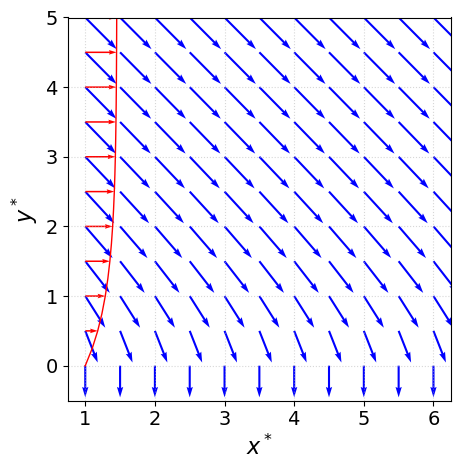

In [3]:
fig, ax = plt.subplots(tight_layout=True)
ax.set_xlabel('$x^*$')
ax.set_ylabel('$y^*$')
ax.set_ylim(-0.5, 5)
ax.set_aspect('equal', 'box')
ax.grid(alpha=0.5, linestyle='dotted')

x, y = np.meshgrid(np.linspace(1, 6, num=11),  # region of interest away from x=0
                     np.linspace(0, 5, num=11))

ax.quiver(x, y, vx(x, y), vy(x, y),
          scale=2.2, scale_units='xy', color='blue')

# add v_x example arrows and the envelope of v_x magnitude,
# shift by 1 and multiply by 1/2.2 because we scaled the arrows in the quiver by 2.2
yy = np.linspace(0, 5, num=21)
ax.plot(1 + 1/2.2*vx(x, yy), yy, color='red', linewidth='1')

yy = yy[::2]
ax.quiver(np.ones_like(yy), yy, vx(1, yy), np.zeros_like(yy), scale=2.2,
          scale_units='xy', color='red', width=0.004)

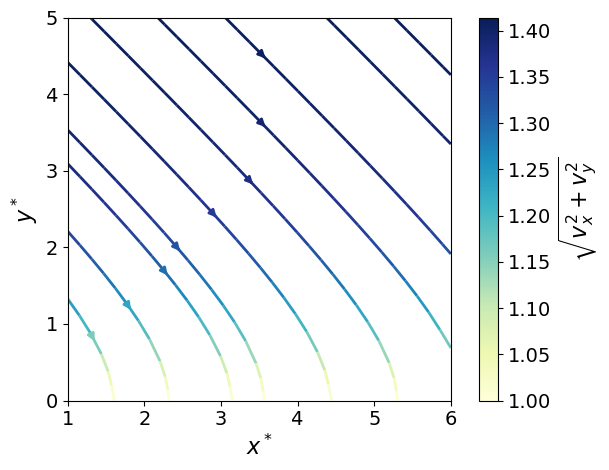

In [4]:
fig, ax = plt.subplots(tight_layout=True)
ax.set_xlabel('$x^*$')
ax.set_ylabel('$y^*$')
ax.set_ylim(0, 5)
ax.set_aspect('equal', 'box')

x, y = np.meshgrid(np.linspace(1, 6, num=501),  # region of interest away from x=0
                     np.linspace(0, 15, num=501))

# customize the streamlines
starty = np.linspace(0.001, 15, num=35)
startx = np.ones_like(starty)
start = np.column_stack((startx, starty))

strm = ax.streamplot(x, y, vx(x, y), vy(x, y),
                     color=np.sqrt(vx(x, y)**2+vy(x, y)**2),
                     linewidth=2, cmap='YlGnBu', start_points=start)

plt.colorbar(strm.lines, label=r'$\sqrt{v_x^2+v_y^2}$');

## The streamfunction

We also solve for the streamfunction $\psi(x,y)$ of this 2D planar flow, either from the governing equations at the outset, or from the obtained velocity field and the relations $v_x = \partial_y \psi$, $v_y = -\partial_x \psi$. Either way, in dimensional variables:
$$
    \psi(x,y) = V x + U y + \frac{U\nu}{V} \big[ e^{-Vy/\nu} - 1\big].
$$
In dimensionless variables:
$$
    \psi^*(x^*,y^*) = \frac{\psi(x,y)}{U\nu/V} = \frac{V^2\ell}{U\nu} x^* + y^* + e^{-y^*} - 1.
$$

**Caution:** $v_x^* \ne \partial_{y^*} \psi^*$, $v_y^* \ne -\partial_{x^*} \psi^*$ in dimensionless form. You'd have to derive the appropriate relations by making the original ones dimensionless.


In [5]:
# setting the coefficient of x^* to 1 without loss of generality
def psi(xs, ys):
    return xs + ys + np.exp(-ys) - 1

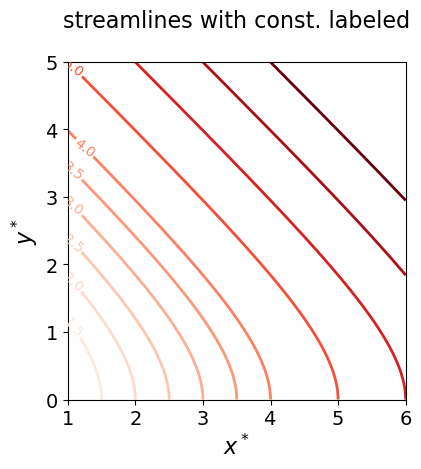

In [6]:
fig, ax = plt.subplots(tight_layout=True)
ax.set_xlabel('$x^*$')
ax.set_ylabel('$y^*$')
ax.set_ylim(0, 5)
ax.set_aspect('equal', 'box')

ax.set_title('streamlines with ''const.'' labeled')

# shift psi by an arbitrary value to make the plot look nicer
zp = psi(x, y)

# you can specify the values of the 'const.'s in psi(x,y) = const.
# or let it choose its own by not passing this argument
consts = [1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8]

strm = ax.contour(x, y, zp, consts,
                  # note this function takes linewidthS, plural...
                  linewidths=2,
                  cmap='Reds')

ax.clabel(strm, inline=True, fontsize=10);

## Another laminar "boundary layer thickness"

We can once again ask how far, $y=\delta$, above the porous plate at $y^*=0$ do we have to go before the horizontal velocity reaches $99\%$ of the incoming "free stream" velocity $U$.

This calculation is straightforward:
$$
v_x^*(y^* = \delta^*) = 1 - e^{-\delta^*} = 0.99
$$
or
$$
\delta^* = -\ln 0.01 \approx 4.6
$$
or
$$
\delta = (-\ln 0.01) \frac{\nu}{V} \approx 4.6 \frac{\nu}{V}.
$$
The thickness $\delta$ is independent of time and varies as $\nu$ (to the power 1), unlike Stokes' problems in which the boundary layer thickness went as $\nu^{1/2}$.

We can show it in a plot.


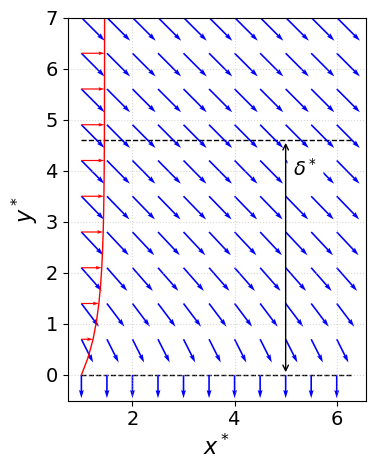

In [11]:
fig, ax = plt.subplots(tight_layout=True)
ax.set_xlabel('$x^*$')
ax.set_ylabel('$y^*$')
ax.set_ylim(-0.5, 7)
ax.set_aspect('equal', 'box')
ax.grid(alpha=0.5, linestyle='dotted')

x, y = np.meshgrid(np.linspace(1, 6, num=11),  # region of interest away from x=0
                     np.linspace(0, 7, num=11))

ax.quiver(x, y, vx(x, y), vy(x, y),
          scale=2.2, scale_units='xy', color='blue')

# add v_x example arrows and the envelope of v_x magnitude,
# shift by 1 and multiply by 1/2.2 because we scaled the arrows in the quiver by 2.2
yy = np.linspace(0, 7, num=21)
ax.plot(1 + 1/2.2*vx(x, yy), yy, color='red', linewidth='1')

yy = yy[::2]
ax.quiver(np.ones_like(yy), yy, vx(1, yy), np.zeros_like(yy), scale=2.2,
          scale_units='xy', color='red', width=0.004)

xx = np.linspace(1, 6.3, num=11)
ax.plot(xx, 4.6*np.ones_like(xx), color='black',
        linewidth=1, linestyle='dashed', zorder=0)
ax.plot(xx, 0*np.ones_like(xx), color='black',
        linewidth=1, linestyle='dashed', zorder=0)

# add nice arrows
ax.text(5.15, 3.9, r'$\delta^*$', fontdict={'size': 14},
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='none'))
# bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.annotate("", (5, 0), (5, 4.6), arrowprops={'arrowstyle': '<->'});

# FURTHER EXPLORATION

On your own:
*   What does the vorticity field look like in this flow?

# REFERENCES

R. L. Panton, _Incompressible Flow_, 4th ed., Wiley, 2013. [doi:10.1002/9781118713075](https://doi.org/10.1002/9781118713075)